# Clase 4 — Tutorial: el operador de Laplace–Beltrami y suavizado por flujo de difusión

**Procesamiento Geométrico y Análisis de Formas** · Ivan Sipiran

> **Versión con soluciones** (ejecutada). Los ejercicios están resueltos en su lugar.

En las slides vimos tres ideas sueltas: que una función se descompone en una base de frecuencias (Fourier), que en una malla el papel de esa base lo juegan los vectores propios del **operador de Laplace–Beltrami**, y que el suavizado por **flujo de difusión** se escribe como
$\mathbf{x}_i \leftarrow \mathbf{x}_i + h\,\lambda\,\Delta \mathbf{x}_i$. En este tutorial las conectamos formalmente:

1. **Qué es $\Delta$** — en $\mathbb{R}^n$, en una superficie, y por qué $\Delta_S \mathbf{x} = -2H\mathbf{n}$ es *la* identidad que explica el suavizado.
2. **Cómo se discretiza** — laplaciano uniforme vs. cotangentes (derivado por elementos finitos), matriz de masa.
3. **Qué hace en frecuencia** — base espectral de la malla, filtro pasa-bajos, y la difusión vista como filtro.
4. **El algoritmo** — Euler explícito (y su límite de estabilidad), Euler implícito (Desbrun et al. 1999), encogimiento y corrección de volumen.

**Cómo usar el notebook.** Hay **8 ejercicios**. Cada uno es una celda `TODO` seguida de una celda de tests (`assert`). Todo se escribe desde cero con NumPy/SciPy/Matplotlib: no hay que instalar ni descargar nada (salvo el bloque opcional del final). Si te quedas atascado, las soluciones están **plegadas al final del notebook**: ejecuta la celda de la solución correspondiente y sigue.

| Bloque | Contenido | Ej. | Min |
|---|---|---|---|
| 0 | Modelos de prueba | — | 5 |
| 1.1 | El laplaciano en $\mathbb{R}^n$: tres lecturas | — | 7 |
| 1.2 | Laplace–Beltrami y $\Delta_S\mathbf{x} = -2H\mathbf{n}$ | — | 6 |
| 1.3 | Laplaciano uniforme | 1 | 6 |
| 1.4 | Laplaciano de cotangentes por elementos finitos | 2 | 13 |
| 1.5 | Matriz de masa y vector de curvatura media | 3 | 8 |
| 2.1 | Base espectral: valores y vectores propios | 4 | 9 |
| 2.2 | Filtro pasa-bajos espectral | 5 | 6 |
| 2.3 | La difusión es un filtro | — | 4 |
| 3.1 | Flujo explícito y estabilidad | 6 | 9 |
| 3.2 | Flujo implícito | 7 | 8 |
| 3.3 | Encogimiento, volumen y experimento final | 8 | 7 |
| 4 | Cierre | — | 2 |
| ★ | Opcional: un escaneo real (Stanford bunny) | — | casa |

In [1]:
#@title Código de apoyo (ejecuta esta celda; no hace falta leerla)
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.linalg as sla
from scipy.spatial import Delaunay
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False})


# ------------------------------------------------------------------ mallas base
def icosphere(level=4):
    """Icosaedro subdividido `level` veces y proyectado a la esfera unitaria."""
    t = (1 + 5 ** 0.5) / 2
    V = np.array([[-1, t, 0], [1, t, 0], [-1, -t, 0], [1, -t, 0],
                  [0, -1, t], [0, 1, t], [0, -1, -t], [0, 1, -t],
                  [t, 0, -1], [t, 0, 1], [-t, 0, -1], [-t, 0, 1]], float)
    F = np.array([[0, 11, 5], [0, 5, 1], [0, 1, 7], [0, 7, 10], [0, 10, 11],
                  [1, 5, 9], [5, 11, 4], [11, 10, 2], [10, 7, 6], [7, 1, 8],
                  [3, 9, 4], [3, 4, 2], [3, 2, 6], [3, 6, 8], [3, 8, 9],
                  [4, 9, 5], [2, 4, 11], [6, 2, 10], [8, 6, 7], [9, 8, 1]])
    V /= np.linalg.norm(V, axis=1, keepdims=True)
    for _ in range(level):
        E = np.sort(np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), axis=1)
        Eu, inv = np.unique(E, axis=0, return_inverse=True)
        inv = inv.ravel()
        Mid = (V[Eu[:, 0]] + V[Eu[:, 1]]) / 2
        Mid /= np.linalg.norm(Mid, axis=1, keepdims=True)
        m = len(F)
        a, b, c = inv[:m] + len(V), inv[m:2 * m] + len(V), inv[2 * m:] + len(V)
        V = np.vstack([V, Mid])
        F = np.vstack([np.c_[F[:, 0], a, c], np.c_[F[:, 1], b, a],
                       np.c_[F[:, 2], c, b], np.c_[a, b, c]])
    return V, F


def warp_sphere(V, a=0.6, d=(0.3, 0.2, 0.93)):
    """Biyección suave de la esfera en sí misma: concentra los vértices hacia `d`.
    La superficie no cambia; sólo cambia el muestreo (malla irregular)."""
    d = np.asarray(d, float); d = d / np.linalg.norm(d)
    W = V + a * d
    return W / np.linalg.norm(W, axis=1, keepdims=True)


def flat_mesh(n=400, seed=0):
    """Malla plana irregular: puntos al azar en [0,1]^2 + Delaunay. z = 0."""
    rng = np.random.default_rng(seed)
    P = np.vstack([rng.random((n, 2)),
                   np.c_[np.linspace(0, 1, 15), np.zeros(15)], np.c_[np.linspace(0, 1, 15), np.ones(15)],
                   np.c_[np.zeros(13), np.linspace(0, 1, 15)[1:-1]], np.c_[np.ones(13), np.linspace(0, 1, 15)[1:-1]]])
    tri = Delaunay(P)
    V = np.c_[P, np.zeros(len(P))]
    F = tri.simplices.copy()
    flip = np.cross(V[F[:, 1]] - V[F[:, 0]], V[F[:, 2]] - V[F[:, 0]])[:, 2] < 0
    F[flip] = F[flip][:, [0, 2, 1]]
    boundary = np.zeros(len(V), bool)
    boundary[np.unique(tri.convex_hull)] = True
    return V, F, boundary


def face_normals(V, F, unit=True):
    N = np.cross(V[F[:, 1]] - V[F[:, 0]], V[F[:, 2]] - V[F[:, 0]])
    if unit:
        N = N / (np.linalg.norm(N, axis=1, keepdims=True) + 1e-300)
    return N


def face_areas(V, F):
    return 0.5 * np.linalg.norm(face_normals(V, F, unit=False), axis=1)


def vertex_normals(V, F):
    """Normales por vértice (promedio de normales de cara ponderado por área)."""
    N = face_normals(V, F, unit=False)
    Nv = np.zeros_like(V)
    for k in range(3):
        np.add.at(Nv, F[:, k], N)
    return Nv / (np.linalg.norm(Nv, axis=1, keepdims=True) + 1e-300)


def edge_lengths(V, F):
    E = np.unique(np.sort(np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), axis=1), axis=0)
    return np.linalg.norm(V[E[:, 0]] - V[E[:, 1]], axis=1)


def fit_sphere(X):
    """Esfera por mínimos cuadrados. Devuelve (centro, radio, max|dist - r| / r)."""
    A = np.c_[2 * X, np.ones(len(X))]
    s = np.linalg.lstsq(A, (X ** 2).sum(1), rcond=None)[0]
    c = s[:3]; r = np.sqrt(s[3] + c @ c)
    return c, r, np.abs(np.linalg.norm(X - c, axis=1) - r).max() / r


def load_obj(path):
    """Lector mínimo de OBJ (sólo triángulos). Elimina vértices no referenciados."""
    V, F = [], []
    for line in open(path):
        if line.startswith('v '):
            V.append([float(x) for x in line.split()[1:4]])
        elif line.startswith('f '):
            F.append([int(x.split('/')[0]) - 1 for x in line.split()[1:4]])
    V, F = np.array(V), np.array(F)
    used, Fc = np.unique(F, return_inverse=True)
    return V[used], Fc.reshape(F.shape)


# ------------------------------------------------------------------ la forma de prueba
# Superficie estrellada R(u)·u: elipsoide + 4 lóbulos grandes + 30 abolladuras medianas.
# Como conocemos R(u) exactamente, podemos medir el error de cualquier malla suavizada.
_LOBES = np.array([[0.8, 0.3, 0.5], [-0.6, 0.7, -0.2], [0.1, -0.8, -0.6], [-0.3, -0.2, 0.95]])
_LOBES /= np.linalg.norm(_LOBES, axis=1, keepdims=True)
_LOBE_A = np.array([0.55, 0.40, 0.45, 0.30])
_LOBE_S = np.array([0.10, 0.14, 0.08, 0.06])
_rng_b = np.random.default_rng(7)
_BUMPS = _rng_b.normal(size=(30, 3)); _BUMPS /= np.linalg.norm(_BUMPS, axis=1, keepdims=True)
_BUMP_A = 0.06 * _rng_b.choice([-1, 1], size=30)
_BUMP_S = 0.010


def blob_radius(U):
    """R(u) de la superficie limpia, para direcciones unitarias U (n x 3)."""
    e = 1.0 / np.sqrt((U[:, 0] / 1.15) ** 2 + U[:, 1] ** 2 + (U[:, 2] / 0.9) ** 2)
    big = (_LOBE_A * np.exp(-(1 - U @ _LOBES.T) / _LOBE_S)).sum(1)
    med = (_BUMP_A * np.exp(-(1 - U @ _BUMPS.T) / _BUMP_S)).sum(1)
    return e * (1 + big + med)


def radial_error(V):
    """|‖x‖ - R(x/‖x‖)| por vértice: distancia (radial) a la superficie limpia."""
    r = np.linalg.norm(V, axis=1)
    return np.abs(r - blob_radius(V / r[:, None]))


def make_blob(level=5, warp=0.6, sigma=0.01, seed=0):
    """(V_limpio, V_ruidoso, F). Malla irregular (esfera deformada por warp_sphere) y
    ruido gaussiano de desviación `sigma` en la dirección normal."""
    U, F = icosphere(level)
    U = warp_sphere(U, warp)
    V0 = blob_radius(U)[:, None] * U
    rng = np.random.default_rng(seed)
    V1 = V0 + sigma * rng.normal(size=(len(V0), 1)) * vertex_normals(V0, F)
    return V0, V1, F


# ------------------------------------------------------------------ visualización
def render(ax, V, F, values=None, cmap='viridis', clim=None, view=(20, -60),
           base=(0.75, 0.78, 0.85), edges=False, title=None, scale=None):
    """Render propio con matplotlib 2D: proyección ortográfica, back-face culling,
    orden por profundidad y sombreado lambertiano. `values` por vértice o por cara."""
    el, az = np.radians(view[0]), np.radians(view[1])
    vd = np.array([np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)])
    right = np.array([-np.sin(az), np.cos(az), 0.0])
    up = np.cross(vd, right)
    P = V - V.mean(0)
    x, y, z = P @ right, P @ up, P @ vd
    N = face_normals(V, F)
    vis = (N @ vd) > 0
    order = np.argsort(z[F[vis]].mean(1))
    Fv = F[vis][order]
    light = 0.8 * vd + 0.35 * up + 0.2 * right
    shade = 0.25 + 0.75 * np.clip(N[vis][order] @ (light / np.linalg.norm(light)), 0, 1)
    if values is None:
        col = np.tile(np.asarray(base, float), (len(Fv), 1))
    else:
        values = np.asarray(values, float)
        fv = values[Fv].mean(1) if len(values) == len(V) else values[vis][order]
        lo, hi = np.percentile(values, [2, 98]) if clim is None else clim
        col = plt.get_cmap(cmap)(np.clip((fv - lo) / (hi - lo + 1e-300), 0, 1))[:, :3]
    col = col * shade[:, None]
    pc = PolyCollection(np.stack([x[Fv], y[Fv]], -1), facecolors=col,
                        edgecolors=(0, 0, 0, 0.35) if edges else col,
                        linewidths=0.2 if edges else 0.3)
    ax.add_collection(pc)
    s = scale if scale is not None else 1.05 * max(np.abs(x).max(), np.abs(y).max())
    ax.set_xlim(-s, s); ax.set_ylim(-s, s); ax.set_aspect('equal'); ax.axis('off')
    if title:
        ax.set_title(title, fontsize=10)


def show(meshes, view=(20, -60), size=3.0, same_scale=True, **kw):
    """meshes: lista de tuplas (V, F, título) o (V, F, título, valores)."""
    fig, axs = plt.subplots(1, len(meshes), figsize=(size * len(meshes), size))
    axs = np.atleast_1d(axs)
    scale = None
    if same_scale:
        scale = 1.02 * max(np.linalg.norm(m[0] - m[0].mean(0), axis=1).max() for m in meshes)
    for ax, m in zip(axs, meshes):
        render(ax, m[0], m[1], values=m[3] if len(m) > 3 else None,
               view=view, title=m[2], scale=scale, **kw)
    plt.tight_layout()
    plt.show()


def ok(msg):
    print('✓ ' + msg)

print('Listo: numpy', np.__version__)

Listo: numpy 2.1.3


## 0. Modelos de prueba (5 min)

Trabajamos con una **superficie sintética cuya forma exacta conocemos**: una superficie estrellada $\mathbf{x}(\mathbf{u}) = R(\mathbf{u})\,\mathbf{u}$ ($\mathbf{u}$ en la esfera unitaria) con tres escalas de detalle: un elipsoide, cuatro lóbulos grandes y treinta abolladuras medianas. Encima le ponemos **ruido gaussiano en la dirección normal** ($\sigma = 0.01$, el tamaño típico de la forma es ~2).

Dos detalles importan:

- Como conocemos $R(\mathbf{u})$, el **error de cualquier malla suavizada se puede medir**: `radial_error(V)` $= |\,\|\mathbf{x}\| - R(\mathbf{x}/\|\mathbf{x}\|)\,|$. Así no discutimos "se ve mejor", sino números.
- La malla es **deliberadamente irregular**: antes de deformar la esfera, `warp_sphere` concentra los vértices hacia un polo. Las aristas varían ~6× de largo. La superficie no cambia, sólo cómo está muestreada. Eso es lo que va a separar al laplaciano uniforme del de cotangentes.

Usamos dos resoluciones: `blob5` (10 242 vértices) para el flujo de difusión y `blob4` (2 562 vértices) para la parte espectral, donde vamos a calcular **todos** los vectores propios.

blob5: 10242 vértices, 20480 caras; arista min/media/max = 0.0204 / 0.0430 / 0.1290
error radial mediano: limpia 0.0e+00, ruidosa 0.0074


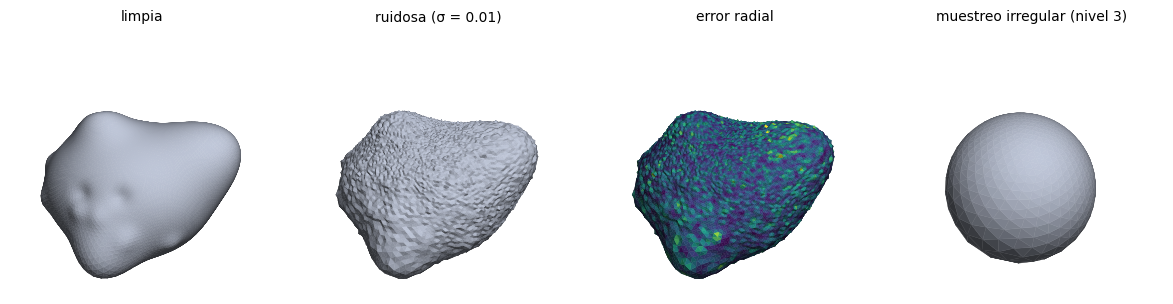

In [2]:
V0, V1, F = make_blob(level=5, sigma=0.01)            # limpia, ruidosa, caras
B0, B1, FB = make_blob(level=4, sigma=0.015)          # versión chica para la parte espectral
el = edge_lengths(V1, F)
print(f'blob5: {len(V1)} vértices, {len(F)} caras; arista min/media/max = '
      f'{el.min():.4f} / {el.mean():.4f} / {el.max():.4f}')
print(f'error radial mediano: limpia {np.median(radial_error(V0)):.1e}, ruidosa {np.median(radial_error(V1)):.4f}')

S3, FS3 = icosphere(3)
show([(V0, F, 'limpia'), (V1, F, 'ruidosa (σ = 0.01)'),
      (V1, F, 'error radial', radial_error(V1)),
      (warp_sphere(S3), FS3, 'muestreo irregular (nivel 3)')], edges=False)

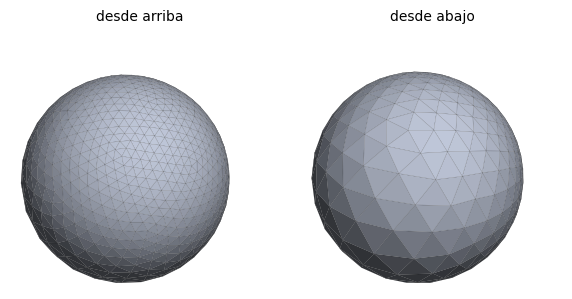

In [3]:
# El muestreo irregular, visto con aristas: denso arriba, ralo abajo.
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
render(ax[0], warp_sphere(S3), FS3, edges=True, view=(60, -60), title='desde arriba')
render(ax[1], warp_sphere(S3), FS3, edges=True, view=(-60, -60), title='desde abajo')
plt.tight_layout(); plt.show()

## 1. El operador de Laplace–Beltrami

### 1.1 El laplaciano en $\mathbb{R}^n$: tres lecturas (7 min)

Para $f:\mathbb{R}^n\to\mathbb{R}$,
$$\Delta f \;=\; \nabla\!\cdot\nabla f \;=\; \sum_{i=1}^n \frac{\partial^2 f}{\partial x_i^2}.$$

Hay tres maneras de leer esta definición, y **cada una se convierte en una discretización o en un algoritmo** más adelante:

**(a) Promedio menos centro.** Si $\bar f_r(\mathbf{x})$ es el promedio de $f$ sobre la esfera de radio $r$ centrada en $\mathbf{x}$,
$$\bar f_r(\mathbf{x}) - f(\mathbf{x}) \;=\; \frac{r^2}{2n}\,\Delta f(\mathbf{x}) + O(r^4).$$
$\Delta f$ mide cuánto se separa $f$ del promedio de sus vecinos. Llevada literalmente a un grafo, esta lectura da el **laplaciano uniforme** (§1.3).

**(b) Gradiente de la energía de Dirichlet.** Sea $E(f) = \tfrac12\int |\nabla f|^2$, que mide cuán "rugosa" es $f$. Para una perturbación $g$ que se anula en el borde, integrando por partes,
$$\frac{d}{d\varepsilon}E(f+\varepsilon g)\Big|_{\varepsilon=0} = \int \nabla f\cdot\nabla g = -\int g\,\Delta f .$$
O sea, $-\Delta f$ es el gradiente de $E$: la ecuación del calor $\partial_t f = \Delta f$ es **descenso de gradiente sobre la rugosidad**. Esta lectura (la *forma débil*) es la que da el **laplaciano de cotangentes** (§1.4).

**(c) Funciones propias = frecuencias.** En $[0, 2\pi)$ periódico, $\Delta e^{ikx} = -k^2 e^{ikx}$: las exponenciales de Fourier son funciones propias de $\Delta$ y el valor propio es la frecuencia al cuadrado. Esta lectura es la que **generaliza Fourier a superficies** (slides 3–5, y §2).

Con (b) y (c) juntas: si $f = \sum_k c_k e^{ikx}$, la ecuación del calor da $c_k(t) = e^{-k^2 t}c_k(0)$. **Las frecuencias altas mueren primero.** Eso es suavizar. Veámoslo en 1D antes de ir a superficies.

error relativo del laplaciano discreto: 1.2e-02


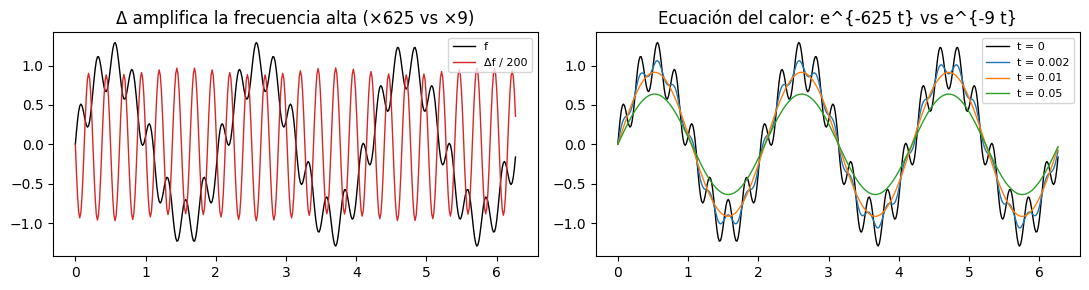

In [4]:
# Señal 1D periódica: frecuencia 3 + frecuencia 25. Diferencias finitas: (f[i+1] - 2 f[i] + f[i-1]) / dx^2
n1 = 400
x = np.linspace(0, 2 * np.pi, n1, endpoint=False); dx = x[1] - x[0]
f = np.sin(3 * x) + 0.3 * np.sin(25 * x)
lap1d = lambda g: (np.roll(g, -1) - 2 * g + np.roll(g, 1)) / dx**2
exact = -9 * np.sin(3 * x) - 0.3 * 625 * np.sin(25 * x)
print(f'error relativo del laplaciano discreto: {np.abs(lap1d(f) - exact).max() / np.abs(exact).max():.1e}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(x, f, 'k', lw=1, label='f'); ax[0].plot(x, lap1d(f) / 200, 'C3', lw=1, label='Δf / 200')
ax[0].set_title('Δ amplifica la frecuencia alta (×625 vs ×9)'); ax[0].legend(fontsize=8)
for t, c in [(0, 'k'), (0.002, 'C0'), (0.01, 'C1'), (0.05, 'C2')]:
    g = f.copy(); steps = int(round(t / 1e-5))
    for _ in range(steps):
        g = g + 1e-5 * lap1d(g)                 # Euler explícito, paso 1e-5
    ax[1].plot(x, g, color=c, lw=1, label=f't = {t}')
ax[1].set_title('Ecuación del calor: e^{-625 t} vs e^{-9 t}'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1.2 Superficies: el operador de Laplace–Beltrami (6 min)

Sea $S$ una superficie y $f:S\to\mathbb{R}$. No hay "$\partial/\partial x_i$" sobre $S$, pero sí:

- **Gradiente en la superficie** $\nabla_S f$: el único vector *tangente* tal que, para toda curva $\gamma(t)\subset S$, $\frac{d}{dt}f(\gamma(t)) = \nabla_S f\cdot\gamma'(t)$.
- **Divergencia en la superficie** $\operatorname{div}_S$ de un campo tangente (flujo neto por unidad de área, medido dentro de $S$).

y se define el **operador de Laplace–Beltrami**
$$\boxed{\;\Delta_S f = \operatorname{div}_S \nabla_S f\;}$$
Depende sólo de la métrica de la superficie (longitudes medidas *sobre* ella), no de cómo está metida en $\mathbb{R}^3$: es **intrínseco**, invariante a doblar la superficie sin estirarla. Las tres lecturas sobreviven sin cambios: (a) promedio sobre círculos geodésicos, (b) energía $E(f)=\tfrac12\int_S|\nabla_S f|^2\,dA$, (c) funciones propias $\Delta_S e_k = -\lambda_k e_k$ con $0=\lambda_1<\lambda_2\le\dots$, que forman una base ortonormal con $\langle f,g\rangle = \int_S fg\,dA$. Esa es la base de la slide 5.

**Convención de signo.** Usamos $\Delta = \operatorname{div}\nabla$, como en las slides: $\Delta f(v_i) = \sum_j w_{ij}(f(v_j)-f(v_i))$ con pesos positivos. Así $\Delta$ es *semidefinido negativo* y escribimos los valores propios de $-\Delta$, $\lambda_k\ge 0$.

#### La identidad que explica el suavizado

Apliquemos $\Delta_S$ a las **funciones coordenada** $\mathbf{x}=(x,y,z):S\to\mathbb{R}^3$, componente a componente. Resulta:
$$\boxed{\;\Delta_S\,\mathbf{x} \;=\; -2H\,\mathbf{n}\;}$$
con $H = (\kappa_1+\kappa_2)/2$ la **curvatura media** y $\mathbf{n}$ la normal exterior ($H>0$ en una esfera). Para una esfera de radio $r$: $\Delta_S\mathbf{x} = -\tfrac{2}{r}\mathbf{n}$.

Tres consecuencias, que vamos a verificar numéricamente:

1. Difundir las posiciones, $\partial_t\mathbf{x} = \Delta_S\mathbf{x} = -2H\mathbf{n}$, mueve cada punto **en la dirección normal**, con velocidad proporcional a la curvatura media: es el **flujo de curvatura media**. El ruido es curvatura alta, así que se mueve rápido; las zonas planas no se mueven.
2. El movimiento es **puramente normal**: no hay deslizamiento tangencial. El resultado depende de la geometría, no de la triangulación. Un buen $\Delta$ discreto debe heredar esto.
3. $-2H\mathbf{n}$ es el gradiente del **área** (lectura (b) aplicada a $\mathbf{x}$): el flujo es descenso de gradiente sobre el área. Una superficie cerrada **siempre encoge**; una esfera colapsa en tiempo finito, $r(t)^2 = r_0^2 - 4t$.

### 1.3 El laplaciano uniforme (6 min)

La lectura (a) llevada a la malla, ignorando la geometría:
$$\Delta f(v_i) \approx \frac{1}{|\mathcal N_1(v_i)|}\sum_{v_j\in\mathcal N_1(v_i)} \big(f(v_j)-f(v_i)\big),\qquad
\mathbf L_u = \mathbf D^{-1}\mathbf A - \mathbf I,$$
con $\mathbf A$ la matriz de adyacencia (simétrica, binaria) y $\mathbf D=\operatorname{diag}(\text{grado})$. Sólo depende de la **conectividad**. Ojo: es adimensional, así que no aproxima $\Delta_S$ sino algo como $\ell^2\Delta_S$, con $\ell$ el largo de arista *local*. Si $\ell$ varía en la malla, la aproximación varía con ella.

#### Ejercicio 1 — `uniform_laplacian(F, n)`

Construye $\mathbf L_u$ como matriz dispersa $n\times n$ (CSR). Vectorizado: nada de bucles sobre vértices.

*Pista:* las aristas dirigidas de las caras son `(F[:,0],F[:,1])`, `(F[:,1],F[:,2])`, `(F[:,2],F[:,0])`. Arma una `sp.coo_matrix` con unos, simetriza ($\mathbf A + \mathbf A^\top$) y binariza (`> 0`) porque cada arista interior aparece en dos caras.

In [5]:
# Ejercicio 1 — uniform_laplacian
def uniform_laplacian(F, n):
    I = np.concatenate([F[:, 0], F[:, 1], F[:, 2]])
    J = np.concatenate([F[:, 1], F[:, 2], F[:, 0]])
    A = sp.coo_matrix((np.ones(len(I)), (I, J)), shape=(n, n)).tocsr()
    A = ((A + A.T) > 0).astype(float)
    deg = np.asarray(A.sum(axis=1)).ravel()
    return (sp.diags(1.0 / deg) @ A - sp.eye(n)).tocsr()

In [6]:
# Tests del ejercicio 1
# Tetraedro: cada vértice tiene 3 vecinos -> 1/3 fuera de la diagonal
Ft = np.array([[0, 1, 2], [0, 3, 1], [0, 2, 3], [1, 3, 2]])
Lt = uniform_laplacian(Ft, 4).toarray()
assert np.allclose(Lt, np.full((4, 4), 1 / 3) - (1 + 1 / 3) * np.eye(4)), Lt
Lu = uniform_laplacian(F, len(V1))
assert sp.issparse(Lu) and Lu.shape == (len(V1), len(V1))
assert np.allclose(Lu @ np.ones(len(V1)), 0), 'las filas deben sumar 0 (Δ de una constante = 0)'
assert np.allclose(Lu.diagonal(), -1)
deg = Lu.getnnz(axis=1) - 1
assert deg.min() == 5 and deg.max() == 6, 'en un icosaedro subdividido las valencias son 5 y 6'
ok('Ejercicio 1: todos los tests pasan')

✓ Ejercicio 1: todos los tests pasan


**Para pensar.** En una malla **plana**, cualquier función lineal $f(x,y)=ax+by$ tiene $\Delta f=0$. ¿El laplaciano uniforme lo respeta? Probémoslo en una triangulación de Delaunay irregular del cuadrado unitario, aplicando $\mathbf L_u$ a las coordenadas $(x, y)$: $\mathbf L_u\mathbf x$ es justamente el desplazamiento que el suavizado le daría a cada vértice.

|L_u x| en vértices interiores: mediana 0.0168, max 0.0548   (debería ser 0)


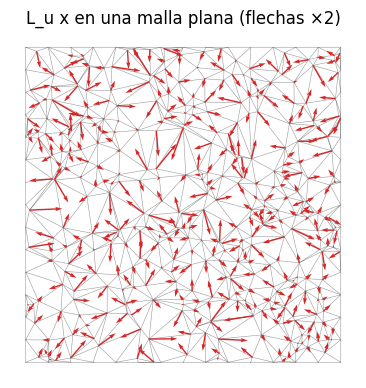

In [7]:
Vp, Fp, bnd = flat_mesh(400)
Lu_p = uniform_laplacian(Fp, len(Vp))
d_unif = Lu_p @ Vp                                  # desplazamiento de cada vértice (en el plano)
print(f'|L_u x| en vértices interiores: mediana {np.median(np.linalg.norm(d_unif[~bnd], axis=1)):.4f}, '
      f'max {np.linalg.norm(d_unif[~bnd], axis=1).max():.4f}   (debería ser 0)')
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.triplot(Vp[:, 0], Vp[:, 1], Fp, lw=0.4, color='0.6')
q = ~bnd
ax.quiver(Vp[q, 0], Vp[q, 1], d_unif[q, 0], d_unif[q, 1], color='C3', angles='xy', scale_units='xy', scale=0.5, width=0.004)
ax.set_aspect('equal'); ax.set_title('L_u x en una malla plana (flechas ×2)'); ax.axis('off')
plt.show()

Los vértices se moverían **dentro del plano**, hacia donde la malla es más rala: el laplaciano uniforme "ve curvatura" en un plano. En una superficie curva esto aparece como deslizamiento tangencial de los vértices, y se mezcla con el movimiento normal que sí queremos.

### 1.4 El laplaciano de cotangentes, por elementos finitos (13 min)

Usamos la lectura (b), la forma débil. Representamos $f$ con **funciones sombrero** lineales a trozos: $f_h = \sum_i f_i\,\varphi_i$, con $\varphi_i(v_j)=\delta_{ij}$, lineal en cada triángulo. Multiplicando $\Delta f = g$ por $\varphi_i$ e integrando por partes:
$$\int_S \varphi_i\, g\,dA \;=\; -\int_S \nabla\varphi_i\cdot\nabla f\,dA
\quad\Longrightarrow\quad
\underbrace{\Big(\int\varphi_i\varphi_j\Big)}_{\mathbf M_{ij}}\, \mathbf g \;=\; \underbrace{\Big(-\int\nabla\varphi_i\cdot\nabla\varphi_j\Big)}_{\mathbf C_{ij}}\,\mathbf f .$$

Así que $\Delta \approx \mathbf M^{-1}\mathbf C$: una **matriz de rigidez** $\mathbf C$ y una **matriz de masa** $\mathbf M$. Calculemos $\mathbf C$.

**En un triángulo** $T$ con vértices $i,j,k$ y área $A_T$: $\varphi_i$ es lineal, vale 1 en $i$ y 0 en la arista opuesta $\mathbf e_i$, así que $\nabla\varphi_i = \frac{\mathbf n\times\mathbf e_i}{2A_T}$ (perpendicular a $\mathbf e_i$, de largo 1/altura). Entonces
$$\int_T\nabla\varphi_i\cdot\nabla\varphi_j = A_T\,\frac{\mathbf e_i\cdot\mathbf e_j}{4A_T^2}
= \frac{-|\mathbf e_i||\mathbf e_j|\cos\theta_k}{2\,|\mathbf e_i||\mathbf e_j|\sin\theta_k} = -\tfrac12\cot\theta_k ,$$
donde $\theta_k$ es el ángulo en el **vértice opuesto** a la arista $ij$. Sumando los dos triángulos que comparten la arista $ij$ (ángulos opuestos $\alpha_{ij}$ y $\beta_{ij}$):
$$\mathbf C_{ij} = \tfrac12\big(\cot\alpha_{ij}+\cot\beta_{ij}\big)\quad(i\neq j\text{ vecinos}),\qquad \mathbf C_{ii} = -\sum_{j\ne i}\mathbf C_{ij}.$$
La diagonal sale de que $\sum_j\varphi_j\equiv1$, así que $\sum_j\nabla\varphi_j = 0$: las filas suman cero.

Con la masa concentrada en la diagonal ($A_i$ = área asociada al vértice $i$):
$$\Delta f(v_i) \approx \frac{1}{2A_i}\sum_{j\in\mathcal N_1(i)}\big(\cot\alpha_{ij}+\cot\beta_{ij}\big)\big(f_j-f_i\big),$$
que es exactamente la forma de la slide 4 con $w_{ij} = (\cot\alpha_{ij}+\cot\beta_{ij})/(2A_i)$. (Pinkall & Polthier 1993; Meyer et al. 2003.)

Propiedades de $\mathbf C$: simétrica; filas que suman 0; **semidefinida negativa** (es menos una energía, $-\mathbf f^\top\mathbf C\mathbf f = \int|\nabla f_h|^2\ge0$), incluso si algún peso es negativo (pasa cuando $\alpha+\beta>\pi$, triangulaciones no Delaunay); y **precisión lineal**: en una malla plana, $\mathbf C\mathbf f = 0$ en los vértices interiores para $f$ lineal, porque $f_h = f$ exactamente.

#### Ejercicio 2 — `cotan_matrix(V, F)`

Construye $\mathbf C$ (sparse CSR, $n\times n$). Vectorizado sobre caras: para cada uno de los 3 ángulos de cada triángulo, calcula su cotangente y súmala (×½) a la entrada de la arista **opuesta**, en ambos sentidos. Después arma la diagonal.

*Pista:* en el vértice `o` con aristas $\mathbf u = \mathbf x_i - \mathbf x_o$, $\mathbf v = \mathbf x_j-\mathbf x_o$: $\cot\theta = \dfrac{\mathbf u\cdot\mathbf v}{\|\mathbf u\times\mathbf v\|}$. Las entradas repetidas en una `coo_matrix` se **suman** al convertir a CSR, así que no hace falta agrupar por arista.

In [8]:
# Ejercicio 2 — cotan_matrix
def cotan_matrix(V, F):
    n = V.shape[0]
    rows, cols, vals = [], [], []
    for k in range(3):
        o, i, j = F[:, k], F[:, (k + 1) % 3], F[:, (k + 2) % 3]
        u, v = V[i] - V[o], V[j] - V[o]
        cot = np.einsum('ij,ij->i', u, v) / np.linalg.norm(np.cross(u, v), axis=1)
        rows += [i, j]; cols += [j, i]; vals += [0.5 * cot, 0.5 * cot]
    C = sp.coo_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                      shape=(n, n)).tocsr()
    C = C - sp.diags(np.asarray(C.sum(axis=1)).ravel())
    return C.tocsr()

In [9]:
# Tests del ejercicio 2
# Triángulo equilátero: cot 60° = 1/sqrt(3)
Ve = np.array([[0, 0, 0], [1, 0, 0], [0.5, np.sqrt(3) / 2, 0]])
Ce = cotan_matrix(Ve, np.array([[0, 1, 2]])).toarray()
assert np.allclose(Ce[0, 1], 0.5 / np.sqrt(3)) and np.allclose(Ce[0, 0], -1 / np.sqrt(3)), Ce
# Simetría, filas que suman 0
C = cotan_matrix(V1, F)
assert abs(C - C.T).max() < 1e-12, 'C debe ser simétrica'
assert np.abs(C @ np.ones(len(V1))).max() < 1e-9, 'las filas deben sumar 0'
# Precisión lineal en la malla plana (sólo vértices interiores)
Cp = cotan_matrix(Vp, Fp)
lin = Cp @ (2 * Vp[:, 0] - 3 * Vp[:, 1])
assert np.abs(lin[~bnd]).max() < 1e-10, f'precisión lineal: {np.abs(lin[~bnd]).max():.2e}'
# Energía de Dirichlet: -x^T C x = ∫|∇x|^2 = área del cuadrado = 1
assert np.isclose(-Vp[:, 0] @ Cp @ Vp[:, 0], face_areas(Vp, Fp).sum()), 'energía de Dirichlet'
# Semidefinida negativa
assert (C @ V1[:, 0]) @ V1[:, 0] < 0
ok('Ejercicio 2: todos los tests pasan')

✓ Ejercicio 2: todos los tests pasan


In [10]:
# La misma prueba de la malla plana, ahora con cotangentes (vértices interiores)
d_cot = Cp @ Vp
print(f'|C x| interior: max {np.linalg.norm(d_cot[~bnd], axis=1).max():.1e}   '
      f'(uniforme: {np.linalg.norm(d_unif[~bnd], axis=1).max():.4f})')
def offdiag(Cm):
    W = sp.triu(Cm, k=1).tocoo(); return W.row, W.col, W.data
r_, c_, w_ = offdiag(Cp)
inner = ~bnd[r_] | ~bnd[c_]      # aristas con dos triángulos (no están sobre el borde)
print(f'malla plana (Delaunay): pesos negativos en aristas con algún extremo interior {(w_[inner] < 0).sum()} de {inner.sum()}, '
      f'en aristas entre vértices de borde {(w_[~inner] < 0).sum()} de {(~inner).sum()}')
r_, c_, w_ = offdiag(cotan_matrix(V1, F))
print(f'blob5 ruidosa: pesos negativos {(w_ < 0).sum()} de {len(w_)}')

|C x| interior: max 7.1e-15   (uniforme: 0.0548)
malla plana (Delaunay): pesos negativos en aristas con algún extremo interior 0 de 1253, en aristas entre vértices de borde 33 de 56
blob5 ruidosa: pesos negativos 123 de 30720


### 1.5 Matriz de masa y vector de curvatura media (8 min)

La masa consistente $\mathbf M_{ij} = \int\varphi_i\varphi_j$ no es diagonal. La versión **concentrada** (*lumped*) suma cada fila en la diagonal; para elementos lineales eso da el **área baricéntrica**:
$$A_i = \tfrac13\sum_{T\ni i} A_T .$$
Con eso, $\mathbf L = \mathbf M^{-1}\mathbf C$ y, por la identidad de §1.2,
$$H_i\,\mathbf n_i \;\approx\; -\tfrac12\,(\mathbf L\mathbf X)_i ,$$
donde $\mathbf X$ es la matriz $n\times3$ de posiciones. Aplicar el laplaciano de cotangentes a las coordenadas da directamente el **vector de curvatura media**.

#### Ejercicio 3 — `mass_matrix(V, F)` y `mean_curvature_normal(V, F)`

1. `mass_matrix`: matriz diagonal dispersa con $A_i$ (usa `face_areas` y `np.add.at`).
2. `mean_curvature_normal`: devuelve el arreglo $n\times 3$ $\;-\tfrac12\mathbf M^{-1}\mathbf C\mathbf X$.

In [11]:
# Ejercicio 3 — mass_matrix y mean_curvature_normal
def mass_matrix(V, F):
    a = face_areas(V, F)
    m = np.zeros(V.shape[0])
    for k in range(3):
        np.add.at(m, F[:, k], a / 3)
    return sp.diags(m).tocsr()


def mean_curvature_normal(V, F):
    C, M = cotan_matrix(V, F), mass_matrix(V, F)
    return -0.5 * (C @ V) / M.diagonal()[:, None]

In [12]:
# Tests del ejercicio 3
M = mass_matrix(V1, F)
assert sp.issparse(M) and np.isclose(M.diagonal().sum(), face_areas(V1, F).sum()), 'la masa total = área'
Sr, FSr = icosphere(4); Sr = 2 * warp_sphere(Sr)            # esfera de radio 2, malla irregular
Hn = mean_curvature_normal(Sr, FSr)
nrm = Sr / 2
H = (Hn * nrm).sum(1)
tang = np.linalg.norm(Hn - H[:, None] * nrm, axis=1) / np.linalg.norm(Hn, axis=1)
assert abs(np.median(H) - 0.5) < 1e-3, f'H mediana = {np.median(H):.4f}, esperado 1/r = 0.5'
assert tang.max() < 0.03, f'componente tangencial máxima {tang.max():.3f}'
ok('Ejercicio 3: todos los tests pasan')

✓ Ejercicio 3: todos los tests pasan


**Convergencia.** Midamos el error de $H$ en esferas de radio 2 cada vez más finas (malla irregular), y comparemos con la dirección de $\mathbf L_u\mathbf x$ del laplaciano uniforme. Agregamos una tercera columna con otra masa, el **área de Voronoi** (Meyer et al. 2003), que reparte el área de cada triángulo según el circuncentro y no en tercios.

In [13]:
def voronoi_mass(V, F):
    # Área de Voronoi por vértice (sin el caso obtuso del 'área mixta' de Meyer et al.)
    m = np.zeros(len(V))
    cot = lambda u, v: np.einsum('ij,ij->i', u, v) / np.linalg.norm(np.cross(u, v), axis=1)
    for k in range(3):
        i, j, o = F[:, k], F[:, (k + 1) % 3], F[:, (k + 2) % 3]
        a2 = ((V[j] - V[i]) ** 2).sum(1); b2 = ((V[o] - V[i]) ** 2).sum(1)
        np.add.at(m, i, (a2 * cot(V[i] - V[o], V[j] - V[o]) + b2 * cot(V[i] - V[j], V[o] - V[j])) / 8)
    return m

print('Esferas de radio 2 (1/r = 0.5). Error |H - 1/r| con cotangentes; fracción tangencial |(L_u x)_tan| / |L_u x| con el uniforme.\n')
print(f"{'nivel':>5} {'vértices':>8} | {'baric. mediana':>14} {'baric. máx':>10} | {'Voronoi máx':>11} | {'unif. tang. mediana':>19} {'máx':>6}")
for lv in [2, 3, 4, 5, 6]:
    S, FS = icosphere(lv); S = 2 * warp_sphere(S); nrm = S / 2
    C_ = cotan_matrix(S, FS)
    Hb = (-0.5 * (C_ @ S) / mass_matrix(S, FS).diagonal()[:, None] * nrm).sum(1)
    Hv = (-0.5 * (C_ @ S) / voronoi_mass(S, FS)[:, None] * nrm).sum(1)
    Lx = uniform_laplacian(FS, len(S)) @ S
    tu = np.linalg.norm(Lx - (Lx * nrm).sum(1)[:, None] * nrm, axis=1) / np.linalg.norm(Lx, axis=1)
    print(f'{lv:>5} {len(S):>8} | {np.median(abs(Hb - .5)):>14.1e} {abs(Hb - .5).max():>10.4f} | '
          f'{abs(Hv - .5).max():>11.1e} | {np.median(tu):>19.3f} {tu.max():>6.3f}')

Esferas de radio 2 (1/r = 0.5). Error |H - 1/r| con cotangentes; fracción tangencial |(L_u x)_tan| / |L_u x| con el uniforme.

nivel vértices | baric. mediana baric. máx | Voronoi máx | unif. tang. mediana    máx
    2      162 |        3.0e-03     0.0817 |     8.2e-15 |               0.364  0.731
    3      642 |        7.0e-04     0.0799 |     3.2e-14 |               0.486  0.927
    4     2562 |        1.8e-04     0.0791 |     1.5e-13 |               0.361  0.981
    5    10242 |        4.4e-05     0.0787 |     7.6e-13 |               0.255  0.995
    6    40962 |        1.1e-05     0.0785 |     3.5e-12 |               0.216  0.999


Tres lecturas de la tabla:

- **Cotangentes + masa baricéntrica**: el error *mediano* baja ~4× por nivel (orden 2 en $\ell$), pero el *máximo* se estanca en ~16 % de $1/r$. Hay convergencia en sentido débil (integrada), no punto a punto. Es un fenómeno conocido del laplaciano de cotangentes en mallas generales (Xu 2004; Hildebrandt, Polthier & Wardetzky 2006).
- **Con área de Voronoi** el error máximo cae a precisión de máquina en esta familia de mallas: $\mathbf C$ es la misma, sólo cambia cómo se normaliza.
- **Uniforme**: la dirección de $\mathbf L_u\mathbf x$ tiene una componente tangencial que en mediana baja muy lento al refinar, y en el peor vértice es casi toda tangencial en todos los niveles.

Para el suavizado vamos a usar $\mathbf C$ y $\mathbf M$ en la forma $(\mathbf M - h\mathbf C)$, o sea en forma débil, donde la masa baricéntrica funciona bien. Pero la tabla es un buen recordatorio de que "$\mathbf M^{-1}\mathbf C\mathbf x$ en un vértice" no siempre es un buen estimador puntual de curvatura.

Ahora miremos la curvatura media en la forma de prueba. **El ruido es curvatura alta**: por eso el flujo de curvatura media lo elimina primero.

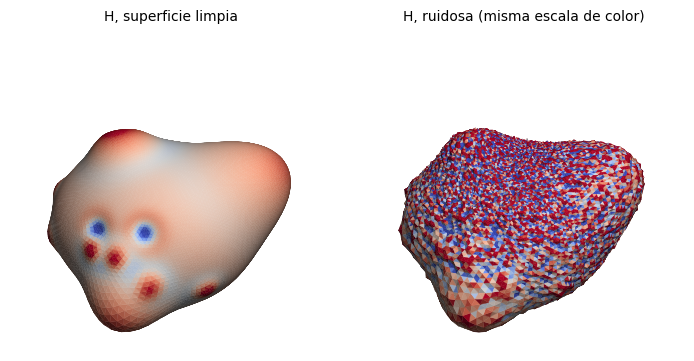

H limpia en [-2.13, 3.67];  H ruidosa en [-29.8, 29.8]  (percentiles 1-99)


In [14]:
def signed_H(V, F):
    return (mean_curvature_normal(V, F) * vertex_normals(V, F)).sum(1)

H0, H1 = signed_H(V0, F), signed_H(V1, F)
lim = np.abs(np.percentile(H0, [1, 99])).max()
show([(V0, F, 'H, superficie limpia', H0), (V1, F, 'H, ruidosa (misma escala de color)', H1)],
     cmap='coolwarm', clim=(-lim, lim), size=3.6)
print(f'H limpia en [{np.percentile(H0, 1):.2f}, {np.percentile(H0, 99):.2f}];  '
      f'H ruidosa en [{np.percentile(H1, 1):.1f}, {np.percentile(H1, 99):.1f}]  (percentiles 1-99)')

## 2. El laplaciano en frecuencia

### 2.1 Base espectral: valores y vectores propios (9 min)

Discretizamos $\Delta_S e = -\lambda e$ en forma débil, con las mismas matrices: es un **problema de valores propios generalizado**
$$-\mathbf C\,\mathbf e_k = \lambda_k\,\mathbf M\,\mathbf e_k,\qquad 0=\lambda_1\le\lambda_2\le\dots\le\lambda_n .$$
Como $-\mathbf C$ es simétrica semidefinida positiva y $\mathbf M$ es definida positiva, los $\lambda_k$ son reales $\ge0$ y los vectores propios son **$\mathbf M$-ortonormales**: $\mathbf E^\top\mathbf M\mathbf E = \mathbf I$. El producto interno correcto es
$$\langle \mathbf f,\mathbf g\rangle_{\mathbf M} = \mathbf f^\top\mathbf M\mathbf g \;\approx\; \int_S f g\,dA ,$$
no el producto punto: con el producto punto, una zona con muchos vértices pesaría más que una zona rala del mismo tamaño.

(Resolver $-\mathbf L\mathbf e=\lambda\mathbf e$ con $\mathbf L=\mathbf M^{-1}\mathbf C$ da los mismos $\lambda_k$, pero $\mathbf L$ no es simétrica. La forma generalizada conserva la simetría y es lo que usan los *solvers*.)

**Prueba de fuego: la esfera unitaria.** Sus funciones propias son los **armónicos esféricos** $Y_\ell^m$, con $\lambda = \ell(\ell+1)$ y multiplicidad $2\ell+1$: un valor propio 0, tres iguales a 2, cinco iguales a 6, siete iguales a 12, nueve iguales a 20, …

#### Ejercicio 4 — `laplacian_eigs(C, M, k=None)`

Devuelve `(lam, E)` ordenados de menor a mayor.

- `k=None`: **todos**, con el solver denso `sla.eigh(A, B)`, que resuelve $\mathbf A\mathbf e = \lambda\mathbf B\mathbf e$ (convierte con `.toarray()`). Sirve hasta unos pocos miles de vértices.
- `k` entero: los `k` más chicos con `spla.eigsh(-C, k=k, M=M, sigma=-1e-8, which='LM')`. `sigma` activa el modo *shift-invert*: se factoriza $-\mathbf C - \sigma\mathbf M$ una vez y se buscan los valores propios **más cercanos a** $\sigma$. Es la manera rápida de obtener las frecuencias bajas de una malla grande. (¿Por qué $\sigma=-10^{-8}$ y no $0$?)

In [15]:
# Ejercicio 4 — laplacian_eigs
def laplacian_eigs(C, M, k=None):
    if k is None:
        lam, E = sla.eigh(-C.toarray(), M.toarray())
    else:
        lam, E = spla.eigsh(-C, k=k, M=M, sigma=-1e-8, which='LM')
    idx = np.argsort(lam)
    return lam[idx], E[:, idx]

In [16]:
# Tests del ejercicio 4
S, FS = icosphere(4); S = warp_sphere(S)               # esfera unitaria, malla irregular
Cs, Ms = cotan_matrix(S, FS), mass_matrix(S, FS)
lam_s, E_s = laplacian_eigs(Cs, Ms, 25)
assert lam_s.shape == (25,) and E_s.shape == (len(S), 25)
assert abs(lam_s[0]) < 1e-6
for l, a, b in [(1, 1, 4), (2, 4, 9), (3, 9, 16), (4, 16, 25)]:
    assert np.allclose(lam_s[a:b], l * (l + 1), rtol=0.02), (l, lam_s[a:b])
assert np.allclose(E_s.T @ Ms @ E_s, np.eye(25), atol=1e-8), 'los vectores propios deben ser M-ortonormales'
lam_d, E_d = laplacian_eigs(Cs, Ms)
assert lam_d.shape == (len(S),) and np.allclose(lam_d[:25], lam_s, atol=1e-8), 'denso y disperso deben coincidir'
ok('Ejercicio 4: todos los tests pasan')

✓ Ejercicio 4: todos los tests pasan


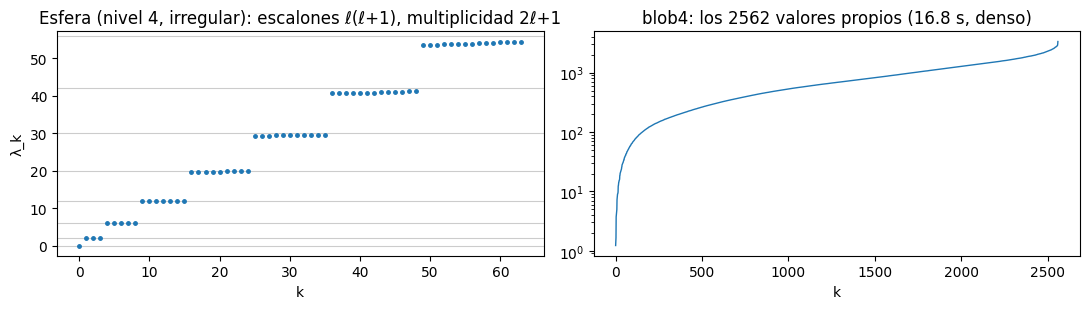

λ_max = 3345.  Recuerda este número: va a reaparecer en §3.1.


In [17]:
# Espectro de la esfera vs l(l+1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(lam_d[:64], '.', ms=5)
for l in range(8):
    ax[0].axhline(l * (l + 1), color='0.8', lw=0.8, zorder=0)
ax[0].set_xlabel('k'); ax[0].set_ylabel('λ_k'); ax[0].set_title('Esfera (nivel 4, irregular): escalones ℓ(ℓ+1), multiplicidad 2ℓ+1')
# Base completa de blob4 ruidosa (2562 vértices)
CB, MB = cotan_matrix(B1, FB), mass_matrix(B1, FB)
t0 = time.time(); lamB, EB = laplacian_eigs(CB, MB); tB = time.time() - t0
ax[1].semilogy(lamB[1:], lw=1); ax[1].set_xlabel('k'); ax[1].set_title(f'blob4: los {len(lamB)} valores propios ({tB:.1f} s, denso)')
plt.tight_layout(); plt.show()
print(f'λ_max = {lamB[-1]:.0f}.  Recuerda este número: va a reaparecer en §3.1.')

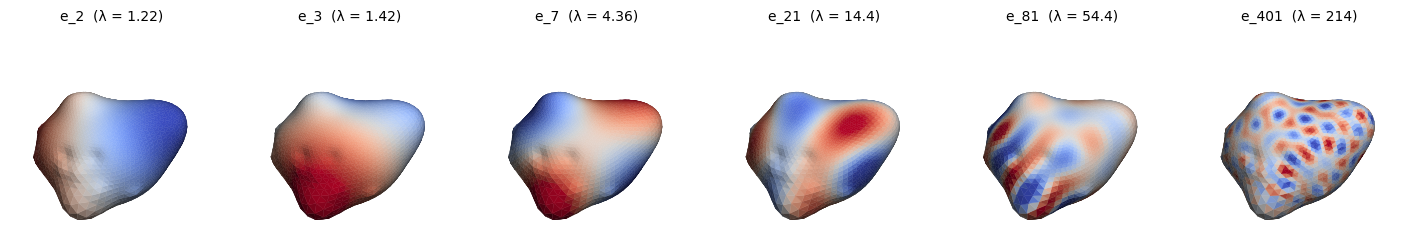

In [18]:
# Algunos vectores propios (dibujados sobre la forma limpia para que se vean mejor)
ks = [1, 2, 6, 20, 80, 400]
show([(B0, FB, f'e_{k+1}  (λ = {lamB[k]:.3g})', EB[:, k]) for k in ks], cmap='coolwarm', size=2.4)

Igual que en Fourier: a mayor $\lambda_k$, más oscilaciones. Los primeros vectores propios son "modos de vibración" de la forma completa. A partir de unos cientos ya oscilan a la escala de las abolladuras, y los últimos, a la escala de una arista.

### 2.2 Filtro pasa-bajos espectral (6 min)

Aplicando la descomposición a cada coordenada (slide 5, con el producto interno $\mathbf M$):
$$\mathbf X = \sum_{k=1}^{n}\mathbf e_k\,\underbrace{\mathbf e_k^\top\mathbf M\mathbf X}_{\mathbf c_k\in\mathbb R^{1\times3}},\qquad
\tilde{\mathbf X}_m = \sum_{k=1}^{m}\mathbf e_k\,\mathbf c_k .$$
Esto son los *manifold harmonics* de Vallet & Lévy (2008), la figura del gárgola de la slide 5.

#### Ejercicio 5 — `spectral_lowpass(X, E, M, m)`

Devuelve $\tilde{\mathbf X}_m$ ($n\times3$). Dos líneas.

In [19]:
# Ejercicio 5 — spectral_lowpass
def spectral_lowpass(X, E, M, m):
    coef = E.T @ (M @ X)          # (n x 3): fila k = <e_k, X>_M
    return E[:, :m] @ coef[:m]

In [20]:
# Tests del ejercicio 5
assert np.allclose(spectral_lowpass(B1, EB, MB, len(B1)), B1, atol=1e-8), 'con m = n se recupera la malla'
X1 = spectral_lowpass(B1, EB, MB, 1)
c_area = MB.diagonal() @ B1 / MB.diagonal().sum()
assert np.allclose(X1, c_area[None, :], atol=1e-8), 'con m = 1 todos los vértices van al centroide (de área)'
assert np.median(radial_error(spectral_lowpass(B1, EB, MB, 150))) < 0.5 * np.median(radial_error(B1))
ok('Ejercicio 5: todos los tests pasan')

✓ Ejercicio 5: todos los tests pasan


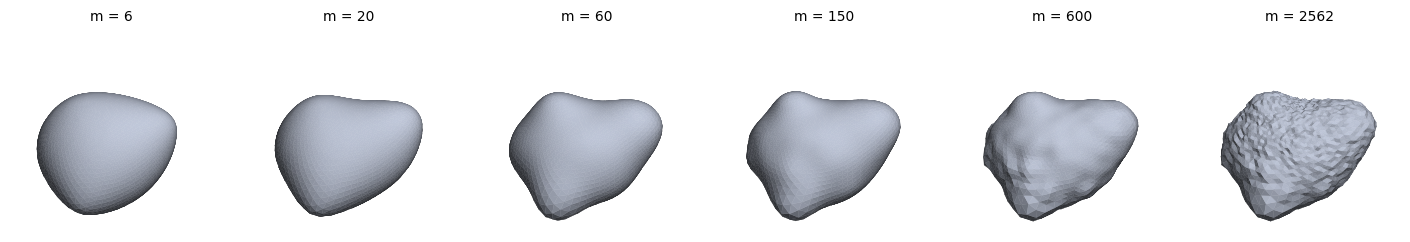

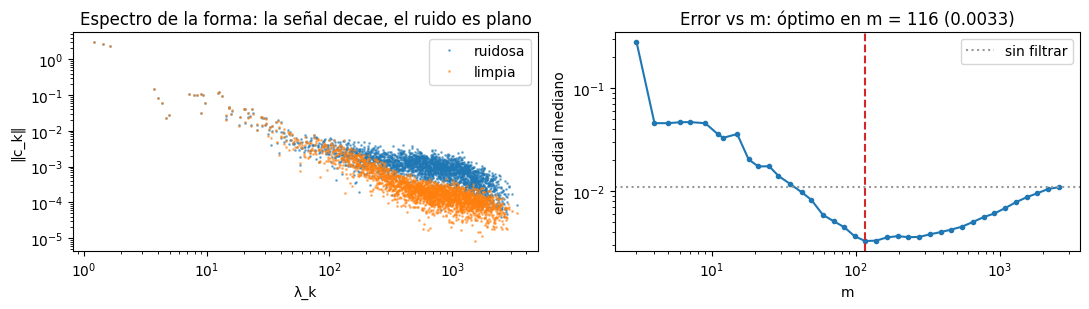

In [21]:
ms = [6, 20, 60, 150, 600, len(B1)]
show([(spectral_lowpass(B1, EB, MB, m), FB, f'm = {m}') for m in ms], size=2.4)

m_grid = np.unique(np.round(np.logspace(0.5, np.log10(len(B1)), 40)).astype(int))
err_m = [np.median(radial_error(spectral_lowpass(B1, EB, MB, m))) for m in m_grid]
m_best = m_grid[int(np.argmin(err_m))]
coef_noisy = EB.T @ (MB @ B1); coef_clean = EB.T @ (MB @ B0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].loglog(lamB[1:], np.linalg.norm(coef_noisy[1:], axis=1), '.', ms=2, alpha=0.5, label='ruidosa')
ax[0].loglog(lamB[1:], np.linalg.norm(coef_clean[1:], axis=1), '.', ms=2, alpha=0.5, label='limpia')
ax[0].set_xlabel('λ_k'); ax[0].set_ylabel('‖c_k‖'); ax[0].legend(); ax[0].set_title('Espectro de la forma: la señal decae, el ruido es plano')
ax[1].loglog(m_grid, err_m, '.-'); ax[1].axvline(m_best, color='C3', ls='--')
ax[1].axhline(np.median(radial_error(B1)), color='0.6', ls=':', label='sin filtrar')
ax[1].set_xlabel('m'); ax[1].set_ylabel('error radial mediano'); ax[1].legend()
ax[1].set_title(f'Error vs m: óptimo en m = {m_best} ({min(err_m):.4f})')
plt.tight_layout(); plt.show()

La figura de la izquierda es el argumento completo del suavizado: **la forma vive en las frecuencias bajas, el ruido se reparte parejo en todas**. Cortar donde el ruido empieza a dominar a la señal da el mínimo error (derecha). Cortar antes se come detalle de verdad: con $m=6$ no están ni los lóbulos, con $m=20$–$60$ aparecen los lóbulos pero no las abolladuras.

El problema práctico: con $n$ grande no podemos calcular todos los vectores propios ($O(n^3)$ con el solver denso), y aún pedir unos cientos con `eigsh` es caro. Necesitamos un filtro que **no requiera la base**. Ahí entra la difusión.

### 2.3 La difusión es un filtro (4 min)

Escribamos la ecuación de difusión de la slide 6 en la base espectral. Si $\mathbf X(t) = \sum_k \mathbf e_k\mathbf c_k(t)$, como $\Delta\mathbf e_k = -\lambda_k\mathbf e_k$:
$$\partial_t\mathbf X = \Delta\mathbf X\quad\Longrightarrow\quad \mathbf c_k(t) = e^{-\lambda_k t}\,\mathbf c_k(0).$$
La difusión es un **filtro pasa-bajos con función de transferencia** $e^{-\lambda t}$: el tiempo $t$ fija la frecuencia de corte ($\lambda\sim 1/t$), sin bordes abruptos.

> **Notación.** En la slide la ecuación es $\partial_t f = \lambda\,\Delta f$, con $\lambda$ el coeficiente de difusión. Aquí $\lambda_k$ son valores propios, así que absorbemos el coeficiente en el tiempo (reescalar $t$): el único parámetro es el paso $h$, y el $h$ de este notebook corresponde al producto $h\lambda$ de la slide.

Y cada esquema de integración temporal es, a su vez, **otro filtro** (sobre cada modo por separado, porque todo es lineal):

| Esquema | Actualización | Factor por paso en el modo $k$ | Tras $N$ pasos ($t=Nh$) |
|---|---|---|---|
| exacto | — | $e^{-h\lambda_k}$ | $e^{-t\lambda_k}$ |
| Euler explícito | $\mathbf X\leftarrow\mathbf X + h\mathbf L\mathbf X$ | $1-h\lambda_k$ | $(1-h\lambda_k)^N$ |
| Euler implícito | $\mathbf X\leftarrow(\mathbf I-h\mathbf L)^{-1}\mathbf X$ | $1/(1+h\lambda_k)$ | $(1+h\lambda_k)^{-N}$ |

Mira la columna del explícito: si $h\lambda_k>2$, entonces $|1-h\lambda_k|>1$ y ese modo **crece** en cada paso. Como en una malla siempre está $\lambda_{\max}$, el explícito es estable sólo si
$$\boxed{\,h < 2/\lambda_{\max}\,}$$

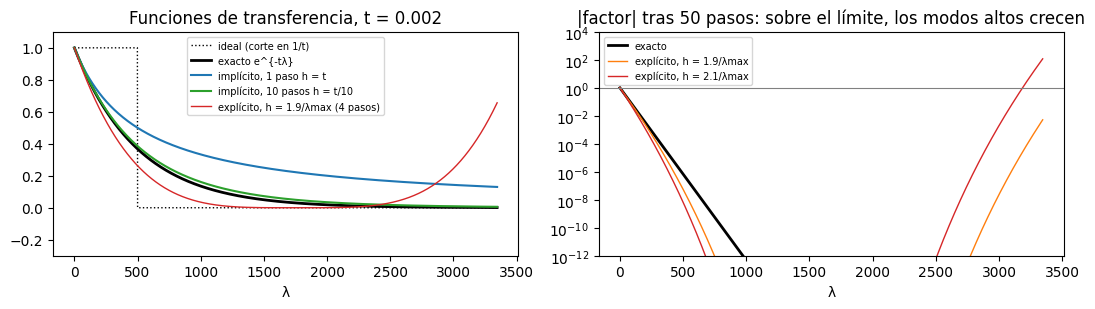

difusión exacta en blob4: mejor t = 2.4e-03, error 0.0056 (pasa-bajos ideal: 0.0033, sin filtrar: 0.0110)


In [22]:
t = 2e-3
lam_ax = np.linspace(0, lamB[-1], 2000)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a in ax:
    a.plot(lam_ax, (lam_ax < 1 / t).astype(float), 'k:', lw=1, label='ideal (corte en 1/t)')
    a.plot(lam_ax, np.exp(-t * lam_ax), 'k', lw=2, label='exacto e^{-tλ}')
    a.plot(lam_ax, 1 / (1 + t * lam_ax), 'C0', label='implícito, 1 paso h = t')
    a.plot(lam_ax, 1 / (1 + t / 10 * lam_ax) ** 10, 'C2', label='implícito, 10 pasos h = t/10')
h_ok, h_bad = 1.9 / lamB[-1], 2.1 / lamB[-1]
N_ok = int(round(t / h_ok))
ax[0].plot(lam_ax, (1 - h_ok * lam_ax) ** N_ok, 'C3', lw=1, label=f'explícito, h = 1.9/λmax ({N_ok} pasos)')
ax[0].set_ylim(-0.3, 1.1); ax[0].set_xlabel('λ'); ax[0].set_title(f'Funciones de transferencia, t = {t}'); ax[0].legend(fontsize=7)
ax[1].cla(); N50 = 50
ax[1].semilogy(lam_ax, np.exp(-N50 * h_ok * lam_ax), 'k', lw=2, label='exacto')
ax[1].semilogy(lam_ax, np.abs(1 - h_ok * lam_ax) ** N50, 'C1', lw=1, label='explícito, h = 1.9/λmax')
ax[1].semilogy(lam_ax, np.abs(1 - h_bad * lam_ax) ** N50, 'C3', lw=1, label='explícito, h = 2.1/λmax')
ax[1].axhline(1, color='0.5', lw=0.8)
ax[1].set_ylim(1e-12, 1e4); ax[1].set_xlabel('λ'); ax[1].set_title(f'|factor| tras {N50} pasos: sobre el límite, los modos altos crecen')
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# Difusión "exacta" (en la base espectral) sobre blob4, para varios t
coef = EB.T @ (MB @ B1)
heat = lambda t: EB @ (np.exp(-t * lamB)[:, None] * coef)
ts = np.logspace(-4, -1, 25)
errs = [np.median(radial_error(heat(t))) for t in ts]
print(f'difusión exacta en blob4: mejor t = {ts[np.argmin(errs)]:.1e}, error {min(errs):.4f} '
      f'(pasa-bajos ideal: {min(err_m):.4f}, sin filtrar: {np.median(radial_error(B1)):.4f})')

Dos cosas en la figura. A la izquierda, el explícito cerca del límite casi no amortigua los modos más altos: el factor $1-h\lambda_{\max}\approx-0.9$ cambia de signo en cada paso, así que esos modos oscilan sin morir. A la derecha, apenas se pasa el límite, los modos altos **crecen** exponencialmente.

Y el número de abajo: la difusión exacta queda peor que el corte ideal. El corte suave $e^{-t\lambda}$ atenúa algo de las frecuencias medias (las abolladuras) antes de eliminar todo el ruido. Es el precio de no calcular la base. A cambio, lo que sigue cuesta un sistema lineal disperso.

## 3. Suavizado por flujo de difusión

### 3.1 El flujo explícito y su límite de estabilidad (9 min)

El algoritmo de la slide 6, en forma matricial:
$$\mathbf X^{(t+1)} = \mathbf X^{(t)} + h\,\mathbf L\,\mathbf X^{(t)}, \qquad \mathbf L = \mathbf M^{-1}\mathbf C .$$

El laplaciano uniforme también cabe en esta forma: $\mathbf L_u = \mathbf D^{-1}(\mathbf A-\mathbf D)$, o sea "$\mathbf C_u = \mathbf A - \mathbf D$, $\mathbf M_u = \mathbf D$". Así el mismo código de estabilidad sirve para los dos.

#### Ejercicio 6 — `smooth_explicit(X, L, h, n_iter)` y `explicit_step_limit(C, M)`

1. `smooth_explicit`: aplica `n_iter` pasos explícitos. **No modifiques** `X` en el lugar.
2. `explicit_step_limit`: devuelve $2/\lambda_{\max}$, con $\lambda_{\max}$ el mayor valor propio de $-\mathbf C\mathbf e = \lambda\mathbf M\mathbf e$. Usa `spla.eigsh(..., k=1, M=M, which='LM', return_eigenvectors=False)` (aquí sin `sigma`: el mayor valor propio es el que el método de Lanczos encuentra más fácilmente).

In [23]:
# Ejercicio 6 — smooth_explicit y explicit_step_limit
def smooth_explicit(X, L, h, n_iter):
    for _ in range(n_iter):
        X = X + h * (L @ X)
    return X


def explicit_step_limit(C, M):
    lmax = spla.eigsh(-C, k=1, M=M, which='LM', return_eigenvectors=False)[0]
    return 2.0 / lmax

In [24]:
# Tests del ejercicio 6
n = len(V1)
Lu = uniform_laplacian(F, n)
Du = sp.diags((Lu.getnnz(axis=1) - 1).astype(float))     # grados
Cu = (Du @ Lu).tocsr()                                    # = A - D
hu = explicit_step_limit(Cu, Du)
assert 1.0 <= hu <= 2.0, f'uniforme: λmax <= 2, así que el límite debe ser >= 1 (dio {hu:.3f})'
C, M = cotan_matrix(V1, F), mass_matrix(V1, F)
L = sp.diags(1 / M.diagonal()) @ C
hc = explicit_step_limit(C, M)
assert np.isclose(2 / hc, abs(spla.eigs(L, k=1, which='LM', return_eigenvectors=False)[0]), rtol=1e-6)
Vcopy = V1.copy()
X_ok = smooth_explicit(V1, L, 0.95 * hc, 200)
assert np.array_equal(V1, Vcopy), 'smooth_explicit no debe modificar su entrada'
X_bad = smooth_explicit(V1, L, 1.05 * hc, 200)
assert np.abs(X_ok).max() < 5 and np.abs(X_bad).max() > 1e3, (np.abs(X_ok).max(), np.abs(X_bad).max())
X_u = smooth_explicit(V1, Lu, 1.05 * hu, 200)
assert np.abs(X_u).max() > 1e3, 'el uniforme también explota sobre su límite'
ok(f'Ejercicio 6: todos los tests pasan  (h_max uniforme = {hu:.3f}, h_max cotangentes = {hc:.2e})')

✓ Ejercicio 6: todos los tests pasan  (h_max uniforme = 1.334, h_max cotangentes = 1.57e-04)


In [25]:
# ¿Cómo escala el límite con la resolución?
print(f"{'malla':>6} {'arista mín':>11} {'h_max unif.':>12} {'h_max cotan.':>13} {'h_max / arista_mín²':>20}")
for name, (Vx, Fx) in {'blob4': (B1, FB), 'blob5': (V1, F)}.items():
    Lx = uniform_laplacian(Fx, len(Vx)); Dx = sp.diags((Lx.getnnz(axis=1) - 1).astype(float))
    hu_ = explicit_step_limit((Dx @ Lx).tocsr(), Dx)
    hc_ = explicit_step_limit(cotan_matrix(Vx, Fx), mass_matrix(Vx, Fx))
    emin = edge_lengths(Vx, Fx).min()
    print(f'{name:>6} {emin:>11.4f} {hu_:>12.3f} {hc_:>13.2e} {hc_ / emin**2:>20.3f}')

 malla  arista mín  h_max unif.  h_max cotan.  h_max / arista_mín²
 blob4      0.0408        1.334      5.98e-04                0.358
 blob5      0.0204        1.334      1.57e-04                0.377


- **Uniforme:** el límite no depende de la malla ($\lambda_{\max}\le 2$ siempre, así que $h\le1$ es seguro). Con $h=1$ el paso es "reemplazar cada vértice por el promedio de sus vecinos".
- **Cotangentes:** $\lambda_{\max}\sim 1/\ell_{\min}^2$. Al refinar una vez, la arista se divide por 2 y el paso máximo por 4 (la última columna es ~constante). Para llegar a un mismo tiempo $t$ hacen falta 4× más pasos, cada uno sobre 4× más vértices. Y el que manda es el **peor** triángulo: en un escaneo real, con astillas, el límite es mucho más chico que $\bar\ell^2$ (lo vas a ver en el bloque opcional). De ahí §3.2.

Antes, el experimento que justifica preferir cotangentes, en el caso más simple posible: suavizar una **esfera** con muestreo irregular. El resultado correcto es obvio: una esfera más chica, con el mismo centro. Iteramos los dos hasta que el área baje a la mitad.

uniforme (h = 0.5)          180 pasos | centro desplazado 0.2402 | desviación máx. de la esfera 14.72 % del radio
cotangentes (h = 5.5e-04)   314 pasos | centro desplazado 0.0000 | desviación máx. de la esfera 0.17 % del radio


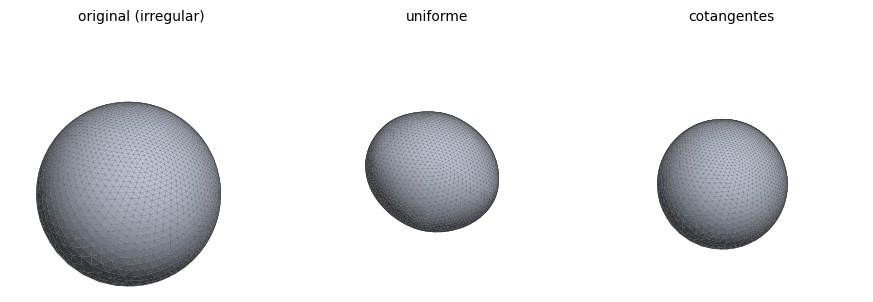

In [26]:
S, FS = icosphere(4); S = warp_sphere(S)
A0 = face_areas(S, FS).sum()
Lu_s = uniform_laplacian(FS, len(S))
Cs, Ms = cotan_matrix(S, FS), mass_matrix(S, FS)
Ls = sp.diags(1 / Ms.diagonal()) @ Cs
hs = 0.9 * explicit_step_limit(Cs, Ms)

def until_half_area(L, h):
    X, it = S.copy(), 0
    while face_areas(X, FS).sum() > 0.5 * A0:
        X = smooth_explicit(X, L, h, 1); it += 1
    return X, it

Xu, itu = until_half_area(Lu_s, 0.5)
Xc, itc = until_half_area(Ls, hs)
for name, X, it in [('uniforme (h = 0.5)', Xu, itu), (f'cotangentes (h = {hs:.1e})', Xc, itc)]:
    c, r, dev = fit_sphere(X)
    print(f'{name:26s} {it:4d} pasos | centro desplazado {np.linalg.norm(c):.4f} | '
          f'desviación máx. de la esfera {100 * dev:.2f} % del radio')
show([(S, FS, 'original (irregular)'), (Xu, FS, 'uniforme'), (Xc, FS, 'cotangentes')], edges=True, view=(10, -60))

El uniforme **deforma la esfera** (huevo, con el centro corrido hacia la zona densa) y además reacomoda los vértices: la malla se ve más pareja, pero la *geometría* cambió según cómo estaba muestreada. El de cotangentes encoge la esfera sobre sí misma, sin moverla: hace lo que dice $\Delta_S\mathbf x = -2H\mathbf n$.

(Lo que el uniforme hace sí es útil para otra cosa: mejorar la calidad de los triángulos. Es la base del *remeshing* tangencial, pero eso no es suavizar la geometría.)

### 3.2 El flujo implícito (8 min)

Desbrun, Meyer, Schröder & Barr (1999): evaluar el laplaciano en el **paso siguiente**,
$$\mathbf X^{(t+1)} = \mathbf X^{(t)} + h\,\mathbf L\,\mathbf X^{(t+1)}
\;\;\Longleftrightarrow\;\;
(\mathbf I - h\mathbf L)\,\mathbf X^{(t+1)} = \mathbf X^{(t)}
\;\;\Longleftrightarrow\;\;
\boxed{(\mathbf M - h\,\mathbf C)\,\mathbf X^{(t+1)} = \mathbf M\,\mathbf X^{(t)}}$$
(multiplicando por $\mathbf M$). La matriz $\mathbf M - h\mathbf C$ es **simétrica definida positiva** para todo $h>0$, y dispersa: se factoriza una vez (Cholesky o LU disperso) y se resuelve para las tres coordenadas. Por la tabla de §2.3 cada modo se multiplica por $1/(1+h\lambda_k)\in(0,1]$: **estable para cualquier $h$**.

**Unidades.** $\mathbf C$ es adimensional y $\mathbf M$ es un área, así que $h$ tiene **unidades de largo²**. Si escalas la malla por $s$, tienes que escalar $h$ por $s^2$. Una forma sensata de elegirlo es $h = \alpha\,\bar\ell^2$, con $\bar\ell$ la arista media.

**¿Operador fijo o actualizado?** Si $\mathbf C$ y $\mathbf M$ se calculan una vez (con la malla inicial) es difusión **lineal**: un filtro fijo. Si se recalculan en cada paso es el **flujo de curvatura media** propiamente tal (Desbrun et al.), que con pasos grandes puede generar singularidades. Kazhdan, Solomon & Ben-Chen (2012) muestran que actualizar **sólo** $\mathbf M$ y dejar $\mathbf C$ fijo evita el problema (*conformalized MCF*). Aquí usamos operador fijo.

#### Ejercicio 7 — `smooth_implicit(X, F, h, n_iter, C=None, M=None)`

Si `C` o `M` vienen en `None`, calcúlalos sobre `X`. Factoriza `M - h*C` **una vez** con `spla.factorized` (pide formato CSC) y resuelve por columnas.

In [27]:
# Ejercicio 7 — smooth_implicit
def smooth_implicit(X, F, h, n_iter, C=None, M=None):
    if C is None:
        C = cotan_matrix(X, F)
    if M is None:
        M = mass_matrix(X, F)
    solve = spla.factorized((M - h * C).tocsc())
    for _ in range(n_iter):
        B = M @ X
        X = np.column_stack([solve(B[:, d]) for d in range(3)])
    return X

In [28]:
# Tests del ejercicio 7
# Debe coincidir EXACTAMENTE con el filtro espectral (1 + h λ)^(-N) (§2.3)
h_, N_ = 1e-3, 3
Xi = smooth_implicit(B1, FB, h_, N_)
Xs = EB @ ((1 + h_ * lamB)[:, None] ** (-N_) * (EB.T @ (MB @ B1)))
assert np.abs(Xi - Xs).max() < 1e-8, f'diferencia con el filtro espectral: {np.abs(Xi - Xs).max():.2e}'
# El centroide (de área) se conserva: 1^T C = 0
mB = MB.diagonal()
assert np.allclose(mB @ Xi / mB.sum(), mB @ B1 / mB.sum(), atol=1e-12)
# Estable para un h absurdo (100 000 veces el límite explícito): todo colapsa al centroide, nada explota
Xh = smooth_implicit(B1, FB, 1e5 * explicit_step_limit(CB, MB), 1)
assert np.isfinite(Xh).all() and np.abs(Xh - mB @ B1 / mB.sum()).max() < 0.05
ok('Ejercicio 7: todos los tests pasan')

✓ Ejercicio 7: todos los tests pasan


     t | explícito: pasos   tiempo   error | implícito (4 pasos): tiempo   error
 0.002 |               14   0.01 s  0.0030 |                      0.19 s  0.0029
 0.020 |              134   0.07 s  0.0270 |                      0.16 s  0.0268
 0.200 |             1338   0.49 s  0.2543 |                      0.16 s  0.2467


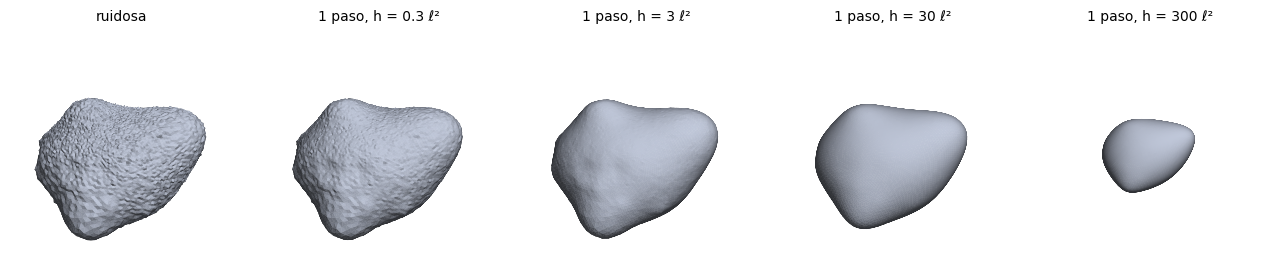

In [29]:
C5, M5 = cotan_matrix(V1, F), mass_matrix(V1, F)
L5 = sp.diags(1 / M5.diagonal()) @ C5
h5 = 0.95 * explicit_step_limit(C5, M5)
print(f"{'t':>6} | {'explícito: pasos':>16} {'tiempo':>8} {'error':>7} | {'implícito (4 pasos): tiempo':>27} {'error':>7}")
for t_target in [0.002, 0.02, 0.2]:
    Ne = int(np.ceil(t_target / h5))
    t0 = time.time(); Xe = smooth_explicit(V1, L5, h5, Ne); te = time.time() - t0
    t0 = time.time(); Xi = smooth_implicit(V1, F, t_target / 4, 4, C5, M5); ti = time.time() - t0
    print(f'{t_target:>6.3f} | {Ne:>16d} {te:>6.2f} s {np.median(radial_error(Xe)):>7.4f} | '
          f'{ti:>25.2f} s {np.median(radial_error(Xi)):>7.4f}')

lbar2 = edge_lengths(V1, F).mean() ** 2
hs_ = [0.3, 3, 30, 300]
show([(V1, F, 'ruidosa')] + [(smooth_implicit(V1, F, a * lbar2, 1, C5, M5), F, f'1 paso, h = {a} ℓ²') for a in hs_],
     size=2.6)

En la tabla: para $t$ chico el explícito es perfectamente competitivo (en Python una multiplicación dispersa es muy barata); su costo crece lineal con $t/h_{\max}$, el del implícito no. Los dos dan el mismo error, porque aproximan la misma difusión.

En las figuras, un solo paso implícito: con $h=3\,\bar\ell^2$ el ruido ya se fue, con $30\,\bar\ell^2$ se van las abolladuras y con $300\,\bar\ell^2$ los lóbulos se redondean. Y se nota otra cosa: **la forma se achica**.

### 3.3 Encogimiento, volumen y el experimento final (7 min)

Encoger no es un error numérico. Es la consecuencia (3) de §1.2: el flujo es descenso de gradiente sobre el área, y la manera más barata de reducir área es encoger. Además, el centroide se conserva, así que todo se contrae hacia él. La corrección más simple (Desbrun et al. 1999) es **reescalar después de cada paso** para recuperar el volumen inicial. El volumen encerrado sale del teorema de la divergencia, sumando tetraedros con vértice en el origen:
$$\operatorname{Vol} = \frac16\sum_{(a,b,c)\in F}\mathbf x_a\cdot(\mathbf x_b\times\mathbf x_c).$$
(Con signo: positivo si las caras están orientadas hacia afuera. No depende del origen si la malla es cerrada.)

#### Ejercicio 8 — `signed_volume(V, F)` y `rescale_volume(X, F, vol0)`

`rescale_volume` escala $\mathbf X$ respecto de su **centroide de área** ($\sum_i A_i\mathbf x_i/\sum_i A_i$, usa tu `mass_matrix`) por el factor $s$ que lleva el volumen a `vol0`. ¿Cuánto vale $s$?

In [30]:
# Ejercicio 8 — signed_volume y rescale_volume
def signed_volume(V, F):
    return np.einsum('ij,ij->i', V[F[:, 0]], np.cross(V[F[:, 1]], V[F[:, 2]])).sum() / 6


def rescale_volume(X, F, vol0):
    m = mass_matrix(X, F).diagonal()
    c = m @ X / m.sum()
    s = (vol0 / signed_volume(X, F)) ** (1 / 3)
    return c + s * (X - c)

In [31]:
# Tests del ejercicio 8
S5, FS5 = icosphere(5)
assert abs(signed_volume(S5, FS5) / (4 / 3 * np.pi) - 1) < 2e-3, signed_volume(S5, FS5)
assert np.isclose(signed_volume(S5 + [3, -1, 2], FS5), signed_volume(S5, FS5)), 'no debe depender de traslaciones'
assert np.isclose(signed_volume(S5, FS5[:, ::-1]), -signed_volume(S5, FS5)), 'invertir la orientación cambia el signo'
assert np.isclose(signed_volume(2 * S5, FS5), 8 * signed_volume(S5, FS5))
vol_n = signed_volume(V1, F)
Xs = smooth_implicit(V1, F, 0.05, 1, C5, M5)
Xr = rescale_volume(Xs, F, vol_n)
assert np.isclose(signed_volume(Xr, F), vol_n), 'el volumen debe quedar en vol0'
m_ = mass_matrix(Xs, F).diagonal()
assert np.allclose(mass_matrix(Xr, F).diagonal() @ Xr / mass_matrix(Xr, F).diagonal().sum(), m_ @ Xs / m_.sum())
ok('Ejercicio 8: todos los tests pasan')

✓ Ejercicio 8: todos los tests pasan


**El experimento final.** Cuatro estrategias sobre `blob5` ruidosa, midiendo el error radial mediano contra la superficie limpia a medida que suavizamos:

- **A** uniforme explícito, $h=0.5$;
- **B** cotangentes implícito, muchos pasos chicos ($h = 10^{-4}$);
- **C** = B + corrección de volumen en cada paso;
- **D** cotangentes implícito, **un solo paso** de tamaño $t$ (el filtro $1/(1+t\lambda)$).

A no tiene "tiempo" comparable (es adimensional), así que va en su propio eje.

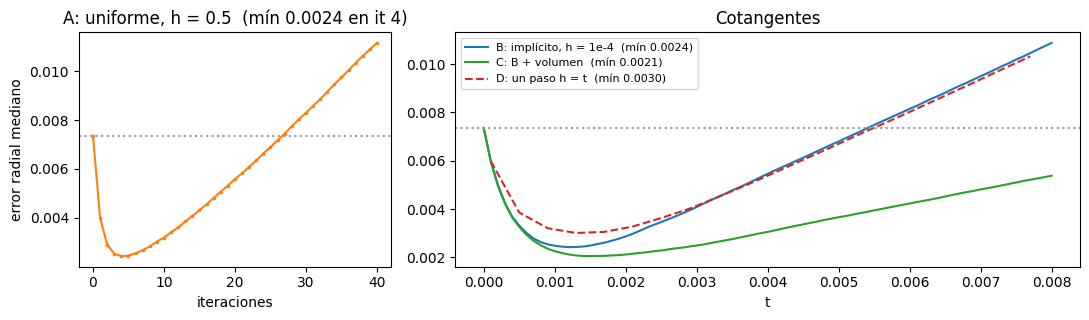

In [32]:
vol_n = signed_volume(V1, F)
med = lambda X: np.median(radial_error(X))
# A: uniforme
Lu5 = uniform_laplacian(F, len(V1))
XA, eA = V1.copy(), [med(V1)]
for _ in range(40):
    XA = smooth_explicit(XA, Lu5, 0.5, 1); eA.append(med(XA))
# B, C: implícito, pasos de 1e-4 (una sola factorización)
hB = 1e-4
solve = spla.factorized((M5 - hB * C5).tocsc())
step = lambda X: np.column_stack([solve((M5 @ X)[:, d]) for d in range(3)])
XB, XC, eB, eC = V1.copy(), V1.copy(), [med(V1)], [med(V1)]
for _ in range(80):
    XB = step(XB); XC = rescale_volume(step(XC), F, vol_n)
    eB.append(med(XB)); eC.append(med(XC))
tB_ = hB * np.arange(81)
# D: un paso de tamaño t
tD = tB_[1:]
eD = [med(smooth_implicit(V1, F, t, 1, C5, M5)) for t in tD[::4]]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={'width_ratios': [1, 2]})
ax[0].plot(eA, 'C1.-', ms=3); ax[0].set_xlabel('iteraciones'); ax[0].set_ylabel('error radial mediano')
ax[0].set_title(f'A: uniforme, h = 0.5  (mín {min(eA):.4f} en it {int(np.argmin(eA))})')
ax[1].plot(tB_, eB, 'C0', label=f'B: implícito, h = 1e-4  (mín {min(eB):.4f})')
ax[1].plot(tB_, eC, 'C2', label=f'C: B + volumen  (mín {min(eC):.4f})')
ax[1].plot(tD[::4], eD, 'C3--', label=f'D: un paso h = t  (mín {min(eD):.4f})')
ax[1].set_xlabel('t'); ax[1].legend(fontsize=8); ax[1].set_title('Cotangentes')
for a in ax:
    a.axhline(med(V1), color='0.6', ls=':')
plt.tight_layout(); plt.show()

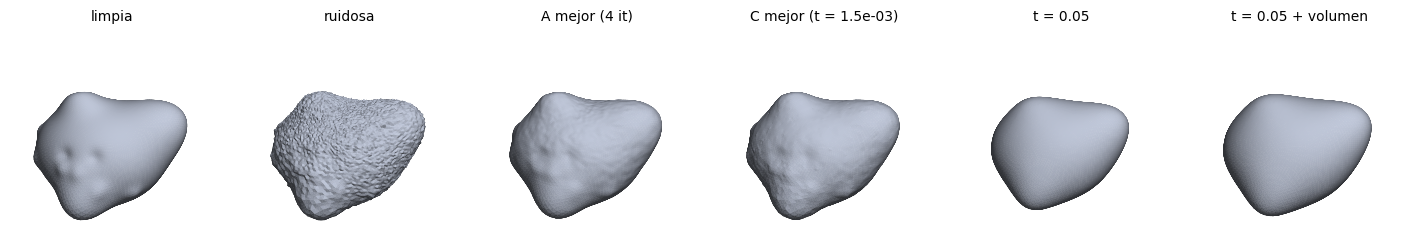

volumen tras t = 0.05: 80.0% del original


In [33]:
# Mejor resultado de cada uno, y qué pasa si suavizamos de más (t = 0.05)
XA_best = smooth_explicit(V1, Lu5, 0.5, int(np.argmin(eA)))
kC = int(np.argmin(eC))
XC_best = V1.copy()
for _ in range(kC):
    XC_best = rescale_volume(step(XC_best), F, vol_n)
X_over = smooth_implicit(V1, F, 0.01, 5, C5, M5)
show([(V0, F, 'limpia'), (V1, F, 'ruidosa'), (XA_best, F, f'A mejor ({int(np.argmin(eA))} it)'),
      (XC_best, F, f'C mejor (t = {tB_[kC]:.1e})'), (X_over, F, 't = 0.05'),
      (rescale_volume(X_over, F, vol_n), F, 't = 0.05 + volumen')], size=2.4)
print(f'volumen tras t = 0.05: {signed_volume(X_over, F) / vol_n:.1%} del original')

Qué mirar en las curvas:

- **Todas tienen forma de U.** Primero se va el ruido (el error baja) y después empiezan a irse las abolladuras de verdad (sube). Hay un $t$ óptimo, y depende del nivel de ruido: en la práctica se elige mirando, no hay una superficie limpia contra la cual medir.
- **B vs D, al mismo $t$:** muchos pasos chicos se acercan al filtro exacto $e^{-t\lambda}$, que corta más parejo. Un paso grande es el filtro $1/(1+t\lambda)$, que deja pasar demasiada frecuencia alta (compara las curvas azul y verde de §2.3). Para denoising conviene más de un paso.
- **C vs B:** la corrección de volumen ayuda más cuanto más suavizas, porque el error de B a $t$ grande es sobre todo encogimiento. No arregla el otro problema: los lóbulos se redondean igual. Un reescalado global no puede devolver detalle local.
- **A** queda en el mismo orden de error que B en esta malla. El uniforme no es inútil para quitar un poco de ruido. Su problema es el de §3.1: el resultado depende del muestreo, y se nota cuando el muestreo es muy irregular o cuando suavizas mucho.

## 4. Cierre (2 min)

| Idea | Dónde apareció |
|---|---|
| $\Delta$ = promedio − centro = −gradiente de la energía de Dirichlet = generador de las frecuencias | §1.1 |
| $\Delta_S\mathbf x = -2H\mathbf n$: difundir posiciones = flujo de curvatura media = descenso sobre el área | §1.2, Ej. 3 |
| Cotangentes = elementos finitos lineales: $\Delta\approx\mathbf M^{-1}\mathbf C$, precisión lineal, sin deslizamiento tangencial | Ej. 2, §3.1 |
| Base espectral: $-\mathbf C\mathbf e=\lambda\mathbf M\mathbf e$, producto interno $\mathbf M$, armónicos esféricos | Ej. 4–5 |
| Difusión = filtro $e^{-t\lambda}$; explícito = $(1-h\lambda)^N$, estable sólo si $h<2/\lambda_{\max}\sim\ell^2$ | §2.3, Ej. 6 |
| Implícito: $(\mathbf M-h\mathbf C)\mathbf X'=\mathbf M\mathbf X$, incondicionalmente estable, $h$ en unidades de largo² | Ej. 7 |
| Encoge por diseño; reescalar el volumen corrige el tamaño, no el detalle perdido | Ej. 8 |

**Lo que el flujo de difusión no hace.** Es **isótropo**: suaviza igual en todas las direcciones, así que redondea aristas vivas y esquinas. Las extensiones que vienen: Taubin $\lambda|\mu$ (1995), que alterna un paso que encoge y uno que infla para un filtro sin encogimiento; difusión **anisótropa** y filtros **bilaterales** sobre normales (Jones et al. 2003, Fleishman et al. 2003), que frenan la difusión a través de aristas vivas.

### Preguntas para discutir

1. En §1.3 el laplaciano uniforme movía vértices en una malla plana. ¿Hacia dónde, y por qué? ¿Qué pasaría en una malla plana *regular* de triángulos equiláteros?
2. La masa baricéntrica no converge punto a punto en $H$, la de Voronoi sí. ¿Por qué eso no importa para el flujo implícito?
3. ¿Por qué `eigsh` con `sigma=0` falla, o se vuelve inestable, para este problema?
4. En el espectro de §2.2 el ruido aparece "plano". ¿Qué forma esperarías para ruido *tangencial*? ¿Lo afecta el suavizado?
5. ¿Qué pasa con $\lambda_{\max}$, y con el paso explícito, si la malla tiene un solo triángulo muy chico (una astilla)? ¿Y con el implícito?
6. Con operador fijo, ¿la esfera de §3.1 colapsa en tiempo finito como predice $r^2 = r_0^2-4t$? ¿Qué predice la tabla de §2.3 para los modos $\ell=1$?
7. Repite el experimento final recalculando $\mathbf C$ y $\mathbf M$ en cada paso (flujo de curvatura media "de verdad"). ¿Cambia el $t$ óptimo? ¿Y si recalculas sólo $\mathbf M$ (Kazhdan et al. 2012)?
8. Si quisieras suavizar una **función** sobre la malla (por ejemplo, un mapa de curvatura ruidoso) y no la geometría, ¿qué cambia en el algoritmo?

### Bibliografía

- M. Botsch, L. Kobbelt, M. Pauly, P. Alliez, B. Lévy. *Polygon Mesh Processing*. AK Peters, 2010. Caps. 3 (curvatura discreta) y 4 (suavizado).
- U. Pinkall, K. Polthier. Computing discrete minimal surfaces and their conjugates. *Experimental Mathematics*, 1993.
- G. Taubin. A signal processing approach to fair surface design. *SIGGRAPH* 1995.
- M. Desbrun, M. Meyer, P. Schröder, A. Barr. Implicit fairing of irregular meshes using diffusion and curvature flow. *SIGGRAPH* 1999.
- M. Meyer, M. Desbrun, P. Schröder, A. Barr. Discrete differential-geometry operators for triangulated 2-manifolds. *VisMath* 2003.
- G. Xu. Convergence of discrete Laplace–Beltrami operators over surfaces. *Computers & Mathematics with Applications*, 2004.
- K. Hildebrandt, K. Polthier, M. Wardetzky. On the convergence of metric and geometric properties of polyhedral surfaces. *Geometriae Dedicata*, 2006.
- M. Wardetzky, S. Mathur, F. Kälberer, E. Grinspun. Discrete Laplace operators: no free lunch. *SGP* 2007.
- B. Vallet, B. Lévy. Spectral geometry processing with manifold harmonics. *Computer Graphics Forum (Eurographics)*, 2008.
- M. Kazhdan, J. Solomon, M. Ben-Chen. Can mean-curvature flow be modified to be non-singular? *Computer Graphics Forum (SGP)*, 2012.
- K. Crane. *Discrete Differential Geometry: An Applied Introduction*. Apuntes del curso, CMU (cap. 6, el laplaciano de cotangentes).

## ★ Opcional (para la casa): un escaneo real

El Stanford bunny (35k vértices) desde el repositorio de Alec Jacobson. Tiene **bordes** (agujeros en la base): ahí las filas de $\mathbf C$ siguen sumando 0 (condición de borde de Neumann natural), y verás que el borde también se contrae. Ojo con la escala: el modelo mide ~0.25 de diagonal, así que $h$ se elige relativo a $\bar\ell^2$.

34834 vértices, 69451 caras, arista media 1.47e-03
límite explícito: h_max = 0.0026 ℓ²  ->  h = 100 ℓ² en explícito serían 38,469 pasos


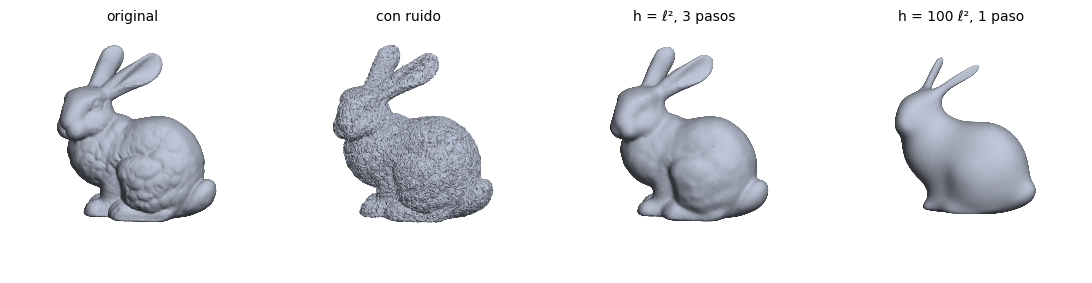

In [34]:
import os, urllib.request
url = 'https://raw.githubusercontent.com/alecjacobson/common-3d-test-models/master/data/stanford-bunny.obj'
try:
    if not os.path.exists('bunny.obj'):
        urllib.request.urlretrieve(url, 'bunny.obj')
    VB, FBn = load_obj('bunny.obj')
    VB = VB[:, [0, 2, 1]] * np.array([1, -1, 1])           # y-arriba -> z-arriba
    lb = edge_lengths(VB, FBn).mean()
    rng = np.random.default_rng(1)
    VBn = VB + 0.3 * lb * rng.normal(size=VB.shape)       # ruido isótropo de 0.3 aristas
    Cb, Mb = cotan_matrix(VBn, FBn), mass_matrix(VBn, FBn)
    print(f'{len(VB)} vértices, {len(FBn)} caras, arista media {lb:.2e}')
    hb = explicit_step_limit(Cb, Mb)
    print(f'límite explícito: h_max = {hb / lb**2:.4f} ℓ²  ->  h = 100 ℓ² en explícito serían {100 * lb**2 / hb:,.0f} pasos')
    show([(VB, FBn, 'original'), (VBn, FBn, 'con ruido'),
          (smooth_implicit(VBn, FBn, lb**2, 3, Cb, Mb), FBn, 'h = ℓ², 3 pasos'),
          (smooth_implicit(VBn, FBn, 100 * lb**2, 1, Cb, Mb), FBn, 'h = 100 ℓ², 1 paso')], view=(15, -70), size=2.8)
except Exception as e:
    print('No se pudo descargar o procesar el modelo:', e)